# Steam EDA

Goal: the facts the **Exploratory Analysis** section needs, and the ones that justify
our modeling and evaluation choices (ranking with leave-one-out, popularity baseline,
`1 + log1p(playtime)` target, uniform negatives).

Each section: the question, why it matters for the write-up, and hints. Keep cells
short; anything reusable moves into `src/`. Save figures you want in the slides to
`cfg.paths.figures`.

In [34]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from assignment_2.modules.config import get_config
from assignment_2.modules.core.plots import log_hist, save, use_style
from assignment_2.modules.data import load_prepped, read_meta


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Style plots
use_style()

In [3]:
cfg = get_config()
print(f"sample={cfg.sample.tag}  seed={cfg.seed}  split={cfg.split.holdout}/{cfg.split.n_holdout}")

t = load_prepped(cfg)
meta = read_meta(cfg)
train = t["interactions_train"]
owned = pd.concat([t[f"interactions_{s}"] for s in ("train", "valid", "test")], ignore_index=True)
items, bundles = t["items"], t["bundles"]
reviews = pd.concat([t[f"reviews_{s}"] for s in ("train", "valid", "test")], ignore_index=True)
sorted(t)

sample=users_0.1  seed=258  split=count/1


['bundles',
 'interactions_test',
 'interactions_test_candidates',
 'interactions_train',
 'interactions_valid',
 'interactions_valid_candidates',
 'items',
 'reviews_test',
 'reviews_train',
 'reviews_valid']

## 1. Dataset summary
The first slide of the EDA section. Built from `meta.json`, so it matches exactly
what `prep` produced.

In [4]:
s = meta["stats"]
rows = {
    "users": s["interactions"]["all"]["users"],
    "games (owned by anyone)": s["interactions"]["all"]["items"],
    "ownership rows": s["interactions"]["all"]["rows"],
    "sparsity": round(s["interactions"]["all"]["sparsity"], 4),
    "train / valid / test rows": "{:,} / {:,} / {:,}".format(
        *(s["interactions"][k]["rows"] for k in ("train", "valid", "test"))
    ),
    "cold held-out rows dropped": s["interactions"]["cold_dropped"],
    "games with metadata": s["items"]["rows"],
    "reviews": s["reviews"]["all"]["rows"],
    "reviews with no year": f"{s['reviews']['undated_share']:.1%}",
    "bundles": s["bundles"]["bundles"],
}
pd.Series(rows, name=cfg.sample.tag).to_frame()

,users_0.1
users,7058
games (owned by anyone),8372
ownership rows,490861
sparsity,0.9917
train / valid / test rows,"477,777 / 6,535 / 6,534"
cold held-out rows dropped,15
games with metadata,32132
reviews,5954
reviews with no year,16.5%
bundles,615


## 2. How concentrated is ownership? (the long tail)
**Why:** if a few games account for most ownership, popularity is a strong baseline,
and that's the bar every model has to clear. It also explains why sampled negatives
are mostly obscure games.

**Do:**
- games per user: `owned.groupby("user_id").size()`; describe() + histogram (log x).
- owners per game: `owned.item_id.value_counts()`; plot rank vs count on log-log axes.
- share of all ownership rows covered by the top 1% / 10% of games
  (sort counts descending, `cumsum() / total`).

**Write-up line:** "The top X% of games account for Y% of ownership."

In [5]:
games_per_user = owned.groupby('user_id').size()
games_per_user.head()

user_id
--000--                  58
-Naughty-                62
-SEVEN-                 394
-SatansLittleHelper-     28
-_skIzZ_-                40
dtype: int64

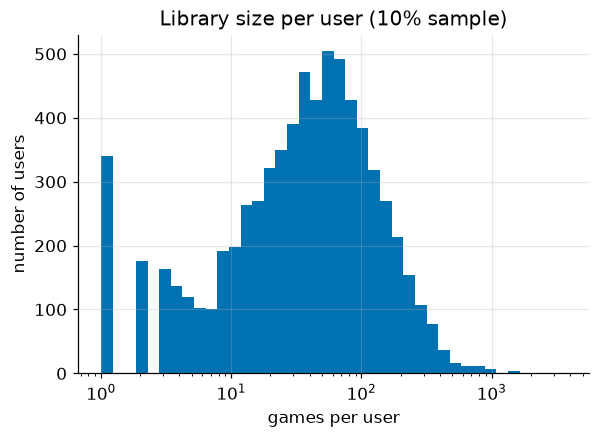

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))   # a figure and one set of axes
log_hist(ax, games_per_user, "games per user", "number of users", "Library size per user (10% sample)")
path = save(fig, "games_per_user")

plt.show()

In [32]:
owners_per_game = owned['item_id'].value_counts()
owners_per_game.describe()

# fig, ax = plt.subplots(figsize=(6, 4))   # a figure and one set of axes
# bins = np.logspace(np.log10(owners_per_game.min()), np.log10(owners_per_game.max()), 40)   # 40 edges from low to high
# counts, edges, patches = ax.hist(owners_per_game, bins=bins)                 # draw on the axes
# ax.set_xscale("log")
# # ax.set_yscale("log")
# ax.set_xlabel("user per game")                     # label everything a reader needs
# ax.set_ylabel("number of players")
# ax.set_title("Player size per game (10% sample)")
# path = save(fig, "owner_per_game")
# plt.show()

count    8357.000000
mean       58.734713
std       201.420084
min         1.000000
25%         2.000000
50%         8.000000
75%        32.000000
max      4905.000000
Name: count, dtype: float64

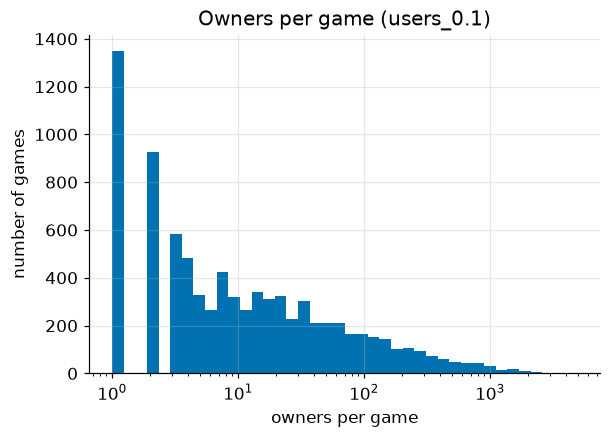

In [36]:
fig, ax = plt.subplots()
log_hist(ax, owners_per_game, "owners per game", "number of games", f"Owners per game ({cfg.sample.tag})")
save(fig, "owners_per_game")
plt.show()

## 3. Playtime: is "owned" the same as "played"?
**Why:** justifies the training target. If many owned games have 0 minutes, ownership
alone is a weak signal; that's why owned rows get `1 + log1p(playtime)`, so
owned-but-unplayed (target 1) stays above not-owned (0).

**Do:**
- share of ownership rows with `playtime_forever == 0`.
- histogram of `np.log1p(playtime_forever)` for played rows (raw playtime is far too
  skewed to plot directly; note the units are minutes).
- per user: share of their library never played. Is it a few users or everyone?

In [8]:
# TODO: zero-playtime share, log1p histogram, per-user unplayed share

## 4. Do popular games get played more?
**Why:** if popularity and playtime are strongly related, the playtime target mostly
re-encodes popularity; if not, it adds signal beyond it (experiment 2 vs 1 in the plan).

**Do:** per game, number of owners vs median `log1p(playtime)` among owners (scatter,
log x). Report a rank correlation (`scipy.stats.spearmanr`).

In [9]:
# TODO: owners vs median playtime per game

## 5. Metadata and bundle coverage
**Why:** genre/tag and bundle features only help games that have them. Coverage
decides whether they're worth building.

**Do:**
- share of owned games (and of ownership *rows*) whose `item_id` is in `items`.
  Rows matter more: popular games dominate rows.
- most common genres among owned games: `items.explode("genres")`, joined to ownership.
- share of owned games that appear in any bundle.

In [10]:
# TODO: metadata coverage (games and rows), top genres, bundle coverage

## 6. Reviews
**Why:** context for the dataset section, and the only data with timestamps.

**Do:**
- share of reviews with `recommend == True`.
- reviews per year (`posted.dt.year.value_counts()`), plus the undated share.
- how many reviewers also appear in the ownership data?

In [11]:
# TODO: recommend rate, reviews per year, overlap with owners

## 7. Evaluation sanity checks
**Why:** confirms the protocol before any model is trusted, and gives the numbers the
Evaluation section cites.

**Do:**
- candidates: positives per user (should be exactly 1 with leave-one-out) and list
  size per user (should be 100).
- popularity gap: mean train popularity of positives vs negatives in
  `interactions_valid_candidates`. A large gap means uniform negatives are easy, so
  popularity will score well; this motivates also reporting popularity-weighted
  negatives.
- random scores: Hit@10 should be ~0.10. Use `ranking_per_user` from
  `assignment_2.modules.core.metrics` with `np.random.default_rng(0).random(len(c))`.
- popularity scores (train owner counts mapped onto candidates): Hit@10 / NDCG@10 is
  the first baseline row of the results table.

In [12]:
c = t["interactions_valid_candidates"]
# TODO: positives and list size per user

In [13]:
# TODO: popularity of positives vs negatives

In [14]:
# TODO: random-score and popularity-score Hit@10 / NDCG@10

## Takeaways (fill in as you go)
- Long tail:
- Playtime:
- Popularity vs playtime:
- Metadata / bundle coverage:
- Evaluation checks: